# XÂY DỰNG MÔ HÌNH HỌC SÂU DỰ ĐOÁN RỦI RO TÍN DỤNG VÀ HỖ TRỢ RA QUYẾT ĐỊNH CẤP KHOẢN VAY

## 1. Mục tiêu & Câu hỏi Nghiên cứu

### Mục tiêu Nghiên cứu
- **Mục tiêu tổng quát:** Nghiên cứu và phát triển hệ thống hỗ trợ quyết định thẩm định rủi ro tín dụng tự động toàn diện dựa trên tập dữ liệu Lending Club. Đề tài ứng dụng kiến trúc Học sâu nâng cao (TabNet / Residual MLP) nhằm dự đoán chính xác xác suất vỡ nợ ($PD$), giải mã các đặc trưng tài chính cốt lõi, quy đổi xác suất thành Thang điểm tín dụng chuẩn tài chính ($PDO$) và tích hợp lên ứng dụng Web Dashboard hỗ trợ ra quyết định thực tế.
- **Mục tiêu cụ thể:**
  1. **Đánh giá hiệu năng mô hình:** Huấn luyện, đánh giá và so sánh năng lực dự đoán rủi ro vỡ nợ của kiến trúc Học sâu nâng cao (TabNet / Residual MLP) so với các mô hình Baseline (Logistic Regression, Random Forest, Simple MLP) thông qua các chỉ số $ROC$-$AUC$, $PR$-$AUC$ và $Macro$-$F1$.
  2. **Giải thích cơ chế nội tại:** Khai thác $Attention$ $Mask$ / Trọng số đặc trưng để làm rõ mức độ tác động của các biến số tài chính - nhân khẩu học ($FICO$, $DTI$, Thu nhập) đến khả năng trả nợ, đảm bảo tính minh bạch kinh doanh.
  3. **Thực nghiệm bóc tách (Ablation Study):** Đánh giá mức độ suy giảm hiệu năng khi lược bỏ các thành phần cấu trúc cốt lõi ($Attention$, $Residual$, $Dropout$, $BatchNorm$) để kiểm chứng vai trò của từng thành phần trong mô hình.
  4. **Tích hợp hệ thống hỗ trợ quyết định (DSS):** Thiết lập công thức quy đổi xác suất $PD$ thành Thang điểm tín dụng ($Credit$ $Score$ via $PDO$), phân tách 5 tầng rủi ro và xây dựng Web Dashboard ($Dash$ + $SQLite$) hỗ trợ chuyên viên thẩm định duyệt vay tự động.

### Câu hỏi Nghiên cứu (Research Questions - RQs)
- **RQ1 (Đánh giá hiệu năng tổng thể):** Kiến trúc học sâu nâng cao (TabNet / Residual MLP) có vượt trội hơn các mô hình học máy truyền thống (Logistic Regression, Random Forest) và mô hình MLP cơ bản về các độ đo $ROC$-$AUC$, $PR$-$AUC$ và $Macro$-$F1$ trong việc dự đoán rủi ro vỡ nợ tín dụng hay không?
- **RQ2 (Khả năng giải thích - Explainability):** Cơ chế $Attention$ $Mask$ của TabNet (hoặc các khối kết nối tắt $Residual$ $Blocks$) tự động trích xuất và trọng số hóa các đặc trưng quan trọng ($FICO$, $DTI$, Thu nhập) có mang lại độ minh bạch cao hơn và phản ánh đúng thực tế kinh doanh tài chính so với mô hình hộp đen thông thường không?
- **RQ3 (Nghiên cứu bóc tách - Ablation Study):** Việc lược bỏ các thành phần cấu trúc cốt lõi của mô hình nâng cao (lược bỏ bước $Attention$/$Residual$, hoặc bỏ $Dropout$/$BatchNorm$) làm suy giảm hiệu năng mô hình như thế nào trên tập validation?
- **RQ4 (Ứng dụng thực tế & Ra quyết định - DSS Integration):** Làm thế nào để quy đổi xác suất $PD$ dự đoán được thành Thang điểm tín dụng ($Credit$ $Score$ via $Points$ $to$ $Double$ $the$ $Odds$ - $PDO$) nhằm phân tách chính xác 5 tầng rủi ro trên Web Dashboard trực quan hỗ trợ chuyên viên thẩm định ra quyết định tự động?

## 2. Tổng quan về dữ liệu
**Bảng Mô Tả Chi Tiết Các Biến Trong Bộ Dữ Liệu Lending Club (Granting Models)**

| Tên biến | Ký hiệu / Đơn vị | Kiểu dữ liệu | Ý nghĩa đặc trưng (Feature Description) |
| :--- | :--- | :--- | :--- |
| id | - | Categorical | Mã định danh duy nhất của từng hồ sơ khoản vay. |
| issue_d | Datetime | Datetime | Mốc thời gian khoản vay được phê duyệt (Tháng và Năm). |
| loan_amnt | USD | Numerical | Số tiền tín dụng mà khách hàng yêu cầu vay. |
| revenue | USD | Numerical | Tổng thu nhập hàng năm do khách hàng tự khai báo trong quá trình đăng ký. |
| dti_n | Tỷ lệ (%) | Numerical | Tỷ lệ nợ trên thu nhập (Debt-to-Income). Hệ số giữa tổng các khoản thanh toán nợ hàng tháng chia cho tổng thu nhập hàng tháng. |
| fico_n | Điểm | Numerical | Điểm rủi ro tín dụng FICO (dao động từ 300 - 850) được ghi nhận tại thời điểm nộp hồ sơ xin vay. |
| emp_length | Năm | Categorical | Thâm niên công tác/Thời gian làm việc của khách hàng (thường dao động từ dưới 1 năm đến 10+ năm). |
| experience_c | 0 / 1 | Categorical | Biến nhị phân xác định khách hàng có phải là người vay mới tại Lending Club hay không (1 = Mới, 0 = Đã từng vay). |
| purpose | - | Categorical | Phân loại mục đích sử dụng của khoản vay do khách hàng chọn. |
| home_ownership_n | - | Categorical | Tình trạng sở hữu nhà ở của khách hàng (Các nhóm: mortgage - thế chấp, rent - thuê, own - sở hữu, other). |
| addr_state | - | Categorical | Tiểu bang cư trú của khách hàng tại Mỹ. |
| zip_code | - | Categorical | 3 chữ số đầu của mã bưu điện (Zip code) nơi khách hàng cư trú. |
| title | - | Text | Tiêu đề tóm tắt về yêu cầu khoản vay do khách hàng cung cấp. |
| desc | - | Text | Phần mô tả chi tiết lý do và mục đích vay vốn do khách hàng tự viết (đã được làm sạch các ký tự HTML). |
| Default | 0 / 1 | Numerical | Biến mục tiêu chính (Target Variable). Xác định trạng thái của khoản vay: 0 $\rightarrow$ Fully Paid (Đã thanh toán đủ), 1 $\rightarrow$ Default (Vỡ nợ). |

*(Ghi chú: Toàn bộ các biến trên đều là những thông tin thô có sẵn ngay tại thời điểm khách hàng nộp hồ sơ, đã được nhà phát hành bộ dữ liệu loại bỏ các thông tin rò rỉ từ tương lai để đảm bảo sự chặt chẽ cho bài toán dự đoán rủi ro).*

## 3. Import thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import copy
import warnings
import os
warnings.filterwarnings('ignore')
import joblib
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import OneHotEncoder
# Các thư viện cho tiền xử lý và mô hình Học sâu (MLP), Học máy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

## 4. Load Data

In [2]:
df = pd.read_csv("LC_loans_granting_model_dataset.csv")

print("Kích thước tập dữ liệu: ", df.shape)

Kích thước tập dữ liệu:  (1347681, 15)


- Tập dữ liệu gồm 1.347.681 dòng (hồ sơ khoản vay) và các cột đặc trưng.

In [3]:
df.head()

,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


## 5. Data Analysis (Phân tích Khám phá Dữ liệu)

In [4]:
pd.set_option("display.max_rows", 100)

# Tạo bảng thống kê chất lượng dữ liệu và giá trị khuyết
cols_df = pd.DataFrame(
    {
        "STT": range(1, len(df.columns) + 1),
        "Tên Cột (Column)": df.columns,
        "Kiểu Dữ Liệu (Dtype)": df.dtypes.values,
        "Số Ô Có Dữ Liệu": df.notnull().sum().values,
        "Số Ô Bị Thiếu (NaN)": df.isnull().sum().values,
        "Tỷ lệ thiếu (%)": (df.isnull().sum().values / len(df) * 100).round(2)
    }
)

cols_df

,STT,Tên Cột (Column),Kiểu Dữ Liệu (Dtype),Số Ô Có Dữ Liệu,Số Ô Bị Thiếu (NaN),Tỷ lệ thiếu (%)
0,1,id,int64,1347681,0,0.00
1,2,issue_d,object,1347681,0,0.00
2,3,revenue,float64,1347681,0,0.00
3,4,dti_n,float64,1347681,0,0.00
4,5,loan_amnt,int64,1347681,0,0.00
5,6,fico_n,float64,1347681,0,0.00
6,7,experience_c,int64,1347681,0,0.00
7,8,emp_length,object,1347681,0,0.00
8,9,purpose,object,1347681,0,0.00
9,10,home_ownership_n,object,1347681,0,0.00


In [5]:
nan_columns = df.isna().sum()
print("Số lượng NaN ở từng cột:")
print(nan_columns[nan_columns > 0])

rows_with_nan = df[df.isna().any(axis=1)]
print(f"\nTổng số dòng chứa NaN trong df: {len(rows_with_nan)}")

display(rows_with_nan.head())

Số lượng NaN ở từng cột:
zip_code          1
title         16657
desc        1228582
dtype: int64

Tổng số dòng chứa NaN trong df: 1228591


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


In [6]:
print("THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ (NUMERICAL):")
display(df.describe().T)

print("\nTHỐNG KÊ MÔ TẢ CÁC BIẾN PHÂN LOẠI (CATEGORICAL):")
display(df.describe(include=['object', 'category']).T)

THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ (NUMERICAL):


,count,mean,std,min,25%,50%,75%,max
id,1347681.0,5.621359e+07,3.839501e+07,54734.0,19706506.00,57664225.00,84495046.00,145636374.0
revenue,1347681.0,7.736968e+04,7.036299e+04,1896.0,46600.00,65000.00,92000.00,10999200.0
dti_n,1347681.0,1.829909e+01,1.115214e+01,0.0,11.82,17.63,24.07,999.0
loan_amnt,1347681.0,1.440823e+04,8.715347e+03,500.0,7975.00,12000.00,20000.00,40000.0
fico_n,1347681.0,6.981589e+02,3.184872e+01,612.0,672.00,692.00,712.00,847.5
experience_c,1347681.0,9.999814e-01,4.306977e-03,0.0,1.00,1.00,1.00,1.0
Default,1347681.0,1.997869e-01,3.998402e-01,0.0,0.00,0.00,0.00,1.0



THỐNG KÊ MÔ TẢ CÁC BIẾN PHÂN LOẠI (CATEGORICAL):


,count,unique,top,freq
issue_d,1347681,139,Mar-2016,48927
emp_length,1347681,12,10+ years,442667
purpose,1347681,14,debt_consolidation,781206
home_ownership_n,1347681,4,MORTGAGE,666594
addr_state,1347681,51,CA,196805
zip_code,1347680,945,945xx,15013
title,1331024,61451,Debt consolidation,661113
desc,119099,109539,Debt consolidation.,1170


### Nhận xét Thống kê mô tả (Descriptive Statistics Analysis)

1. Tình trạng Giá trị Khuyết (Missing Values Analysis):

- Chất lượng biến Mục tiêu ($Default$): Rất lý tưởng. Biến mục tiêu không bị khuyết giá trị ($0$ ô thiếu), đảm bảo tính toàn vẹn tuyệt đối cho nhãn dự đoán.

- Giá trị khuyết ở các Yếu tố Tài chính (Numerical): Các thông tin bắt buộc như $loan\_amnt$ (Số tiền vay), $revenue$ (Thu nhập), $fico\_n$ (Điểm tín dụng) có độ bao phủ dữ liệu rất cao do đây là điều kiện tiên quyết để xét duyệt hồ sơ.

- Giá trị khuyết ở các Yếu tố Văn bản (Text): Các biến như $desc$ (mô tả khoản vay) hoặc $title$ (tiêu đề) thường có tỷ lệ khuyết (Missing Rate) tương đối cao, do không phải khách hàng nào cũng điền phần tự luận này khi đăng ký.

2. Phân tích các Biến số ($revenue, loan\_amnt, fico\_n, dti\_n$):

- Độ lệch & Ngoại lệ bất thường (Extremely High Outliers):

  - $revenue$: Dữ liệu có độ lệch phải (Right-skewed) rất mạnh. Mức thu nhập trung vị (50%) của khách hàng thường xoay quanh $60,000 - 65,000$, nhưng giá trị lớn nhất ($max$) có thể vọt lên tới hàng triệu $USD$.

  - Nhận xét: Sự chênh lệch khổng lồ giữa trung vị và giá trị $max$ chứng tỏ sự tồn tại của các điểm ngoại lệ cực trị. Điều này phản ánh sự phân hóa thu nhập thực tế.

- Khoản vay ($loan\_amnt$): Dao động từ mức vài nghìn đến tối đa khoảng $35,000 - 40,000$. Các mốc phân vị (25%, 50%, 75%) phân bố tương đối đều.

- Tỷ lệ nợ/thu nhập ($dti\_n$): Khoảng giá trị trung bình thường nằm ở mức $15\\% - 20\\%$. Tuy nhiên, có những trường hợp chỉ số này cực kỳ cao, phản ánh các khách hàng đang chịu áp lực trả nợ nặng nề — một rủi ro rất lớn dẫn đến vỡ nợ ($Default$).

- Điểm tín dụng FICO ($fico\_n$): Dao động trong khoảng từ dưới $660$ đến cao nhất là $850$ điểm.

3. Phân tích các Biến phân loại (Categorical Features):

- Mục đích vay ($purpose$): Giá trị xuất hiện nhiều nhất (Mode) là *debt_consolidation* (Gộp nợ) và *credit_card* (Thanh toán thẻ tín dụng). Điều này phản ánh động cơ tài chính chủ yếu của người đi vay tại Lending Club.

- Sở hữu nhà ($home\_ownership\_n$): Tập trung phần lớn vào nhóm *Mortgage* (Đang thế chấp trả góp) và *Rent* (Thuê nhà). Khách hàng thuộc nhóm *Own* (Sở hữu nhà hoàn toàn) chiếm tỷ trọng nhỏ hơn rất nhiều.

###Phân Phối Biến Mục Tiêu Default




**1. Biểu đồ cột (Countplot) - Số lượng hồ sơ theo Trạng thái:**

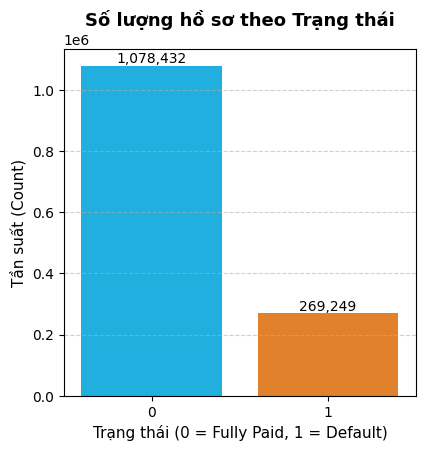

In [7]:
plt.figure(figsize=(10, 4.5))

plt.subplot(1, 2, 1)
ax = sns.countplot(data=df, x='Default', palette=['#00BFFF', '#ff7f0e'])
plt.title('Số lượng hồ sơ theo Trạng thái', fontsize=13, fontweight='bold')
plt.xlabel('Trạng thái (0 = Fully Paid, 1 = Default)', fontsize=11)
plt.ylabel('Tần suất (Count)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=10)


plt.show()

- **Sự chênh lệch số lượng tuyệt đối:** Biểu đồ thể hiện sự áp đảo hoàn toàn của nhóm khách hàng trả nợ tốt (Fully Paid - $0$) với $1,078,432$ hồ sơ.

- Ngược lại, nhóm khách hàng có rủi ro vỡ nợ (Default - $1$) ghi nhận số lượng thấp hơn đáng kể với chỉ $269,249$ hồ sơ đăng ký.

**2. Biểu đồ tròn (Pie Chart) - Tỷ lệ phần trăm Vỡ nợ:**

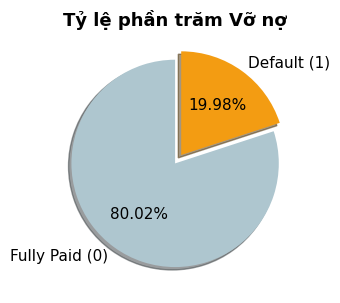

In [8]:
# Biểu đồ tròn (Pie chart)
plt.subplot(1, 2, 2)
class_counts = df['Default'].value_counts()
plt.pie(class_counts, labels=['Fully Paid (0)', 'Default (1)'], autopct='%1.2f%%',
        colors=['#AEC6CF', '#f39c12'], explode=(0, 0.1), shadow=True, startangle=90, textprops={'fontsize': 11})
plt.title('Tỷ lệ phần trăm Vỡ nợ', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

- **Mức độ mất cân bằng dữ liệu:** Tỷ trọng nhóm vỡ nợ chiếm $19.98\%$ so với $80.02\%$ của nhóm thanh toán đủ, minh chứng rõ nét cho hiện tượng **mất cân bằng dữ liệu** (*Imbalanced Data*).

### Phân phối các biến số (Numerical Features)

#### 1. Phân phối biến Số tiền vay ($loan\_amnt$)

**Biểu đồ Histogram & Đường KDE**:

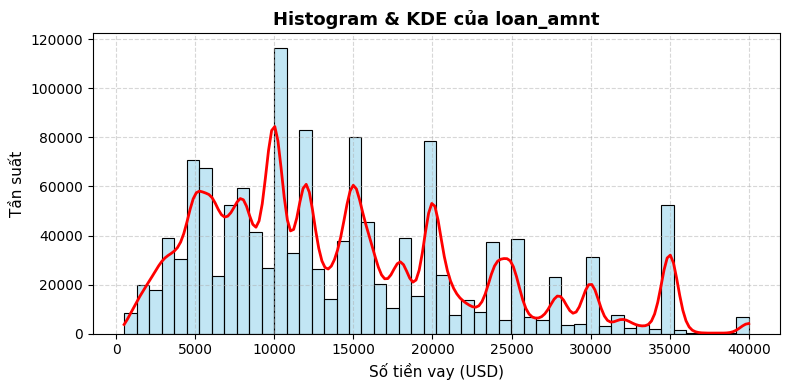

In [9]:
plt.figure(figsize=(8, 4))
ax = sns.histplot(df['loan_amnt'], kde=True, bins=50, color='#87CEEB')

if ax.lines:
    ax.lines[0].set_color('red')
    ax.lines[0].set_linewidth(2)

plt.title('Histogram & KDE của loan_amnt', fontsize=13, fontweight='bold')
plt.xlabel('Số tiền vay (USD)', fontsize=11)
plt.ylabel('Tần suất', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

-  Phân phối: Tập trung chủ yếu từ $5,000$ đến $20,000\,USD$. Đồ thị Histogram hiển thị các đỉnh nhọn cục bộ tại các mốc làm tròn (như $10,000, 15,000, 20,000$), cho thấy tâm lý khách hàng thường yêu cầu vay các con số chẵn.

- Đường cong KDE cho thấy dữ liệu **có nhiều đỉnh** (multimodal), phản ánh thói quen vay theo các gói hạn mức cố định của khách hàng.  

**Biểu đồ Boxplot**

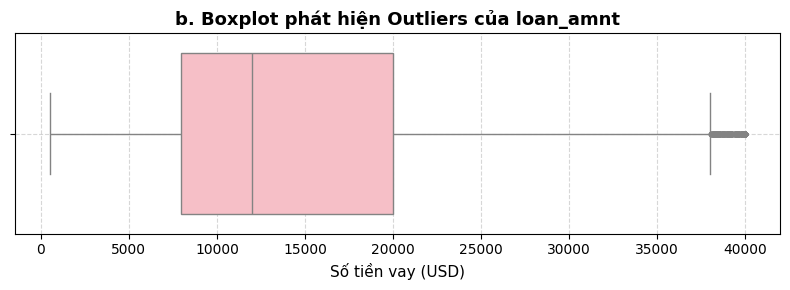

In [10]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['loan_amnt'], color='#FFB6C1', fliersize=3)
plt.title('b. Boxplot phát hiện Outliers của loan_amnt', fontsize=13, fontweight='bold')
plt.xlabel('Số tiền vay (USD)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- Phần lớn các khoản vay tập trung trong khoảng từ $8.000$ USD đến $20.000$ USD, với trung vị (Median) nằm ở khoảng $12.000$ USD.   

- Xuất hiện một nhóm điểm ngoại lai (outliers) nhỏ nằm phía trên mức ngưỡng $38.000$ USD. Tuy nhiên, các giá trị này vẫn nằm trong hạn mức thực tế của sản phẩm vay.

#### 2. Phân phối biến Thu nhập hàng năm ($revenue$)

**Biểu đồ Histogram & Đường KDE:**

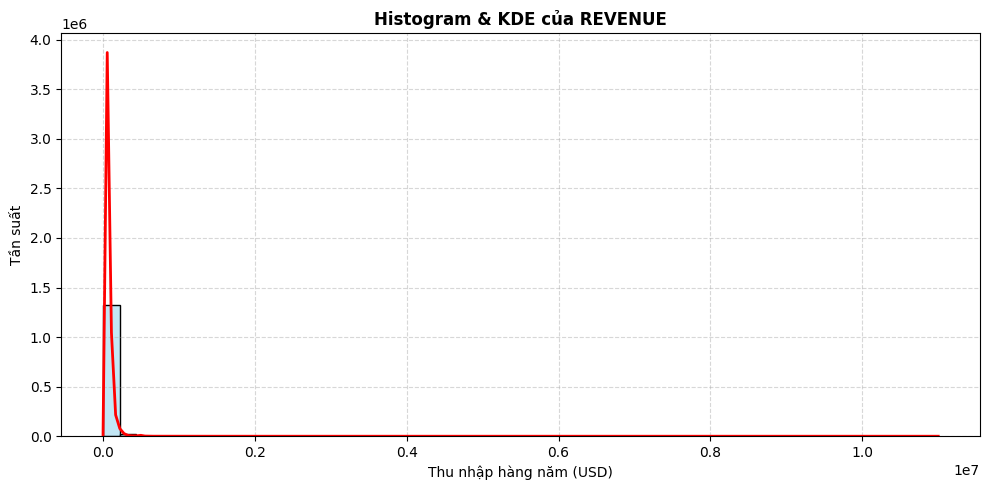

In [11]:
plt.figure(figsize=(10, 5))
ax = sns.histplot(df['revenue'], kde=True, bins=50, color='#87CEEB')

if ax.lines:
    ax.lines[0].set_color('red')
    ax.lines[0].set_linewidth(2)

plt.title('Histogram & KDE của REVENUE', fontsize=12, fontweight='bold')
plt.xlabel('Thu nhập hàng năm (USD)', fontsize=10)
plt.ylabel('Tần suất', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- **Phân phối bị lệch phải cực kỳ nặng (Right-skewed)**. Toàn bộ phần lớn dữ liệu thu nhập của khách hàng bị nén chặt ở góc trái (dưới mức 1 triệu USD), trong khi trục hoành kéo dài đến tận hơn 10 triệu USD do ảnh hưởng của các giá trị cực lớn, thể hiện gần như toàn bộ khách hàng phổ thông có thu nhập dưới $150,000\,USD$/năm

**Biểu đồ Boxplot:**

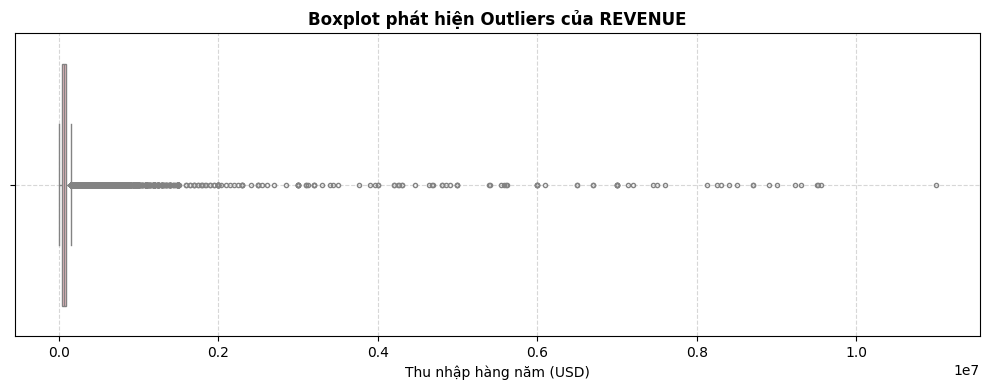

In [12]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['revenue'], color='#FFB6C1', fliersize=3)
plt.title('Boxplot phát hiện Outliers của REVENUE', fontsize=12, fontweight='bold')
plt.xlabel('Thu nhập hàng năm (USD)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- Hộp phân phối chính nằm rất **hẹp ở phía bên trái**, và xuất hiện một chuỗi dài dằng dặc các điểm ngoại lai (outliers) kéo dài vắt ngang sang phía bên phải (lên đến gần $1,1.10^7$ USD).  

#### 3. Phân phối biến Điểm tín dụng ($fico\_n$)

**Biểu đồ Histogram & Đường KDE:**

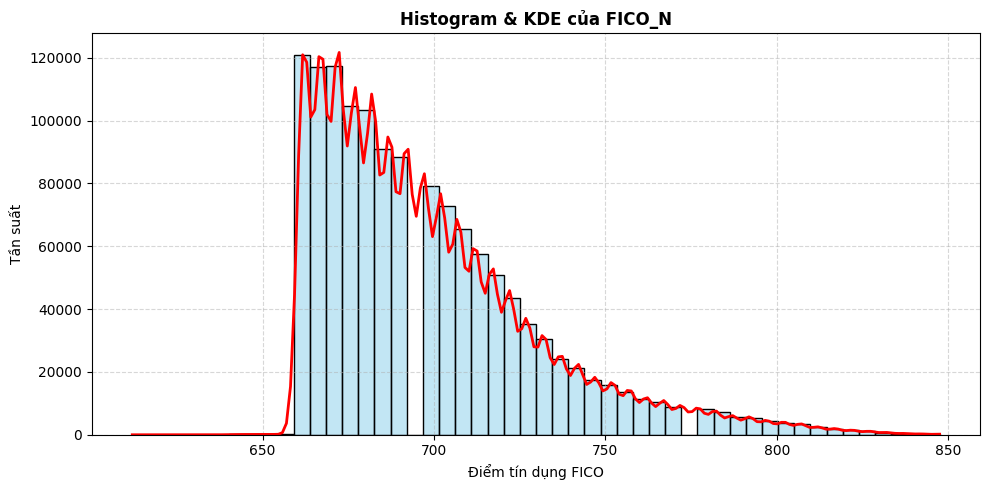

In [13]:
plt.figure(figsize=(10, 5))
ax = sns.histplot(df['fico_n'], kde=True, bins=50, color='#87CEEB')

if ax.lines:
    ax.lines[0].set_color('red')
    ax.lines[0].set_linewidth(2)

plt.title('Histogram & KDE của FICO_N', fontsize=12, fontweight='bold')
plt.xlabel('Điểm tín dụng FICO', fontsize=10)
plt.ylabel('Tần suất', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- Phân phối: Đồ thị bị cắt cứng ở phần đuôi trái (quanh mốc $660$ điểm). Đây là ngưỡng cut-off mặc định để hệ thống cho phép khách hàng nộp hồ sơ vay. Phân phối tập trung đông nhất ở vùng $660 - 720$ điểm và giảm dần khi điểm tiến về mốc tối đa ($850$).

- Đường cong **có hình dáng răng cưa** do điểm FICO trong các tập dữ liệu tín dụng thường được ghi nhận theo từng mốc hoặc dải điểm cụ thể.

**Biểu đồ Boxplot:**

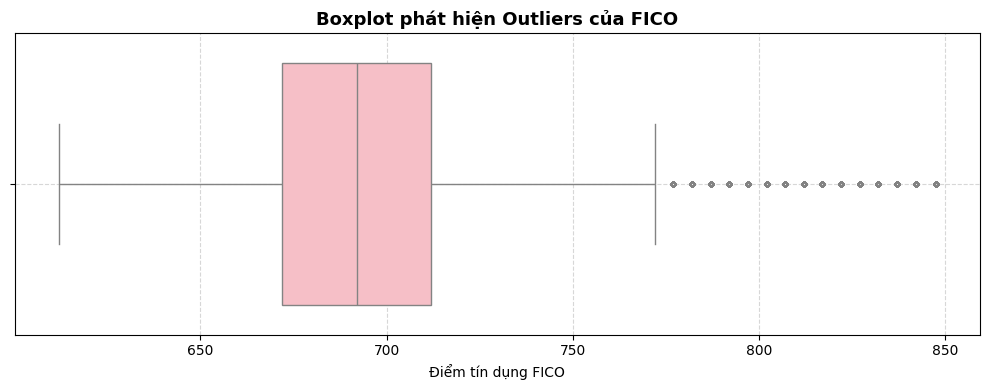

In [14]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['fico_n'], color='#FFB6C1', fliersize=3)
plt.title('Boxplot phát hiện Outliers của FICO', fontsize=13, fontweight='bold')
plt.xlabel('Điểm tín dụng FICO', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- **Phần lớn** khách hàng có điểm FICO nằm trong khoảng từ $~670$ đến $~770$.   

- Xuất hiện **một vài điểm ngoại lai** (outliers) nằm rải rác ở phía **bên phải** (tiệm cận ngưỡng $850$ điểm), đây là nhóm khách hàng có lịch sử tín dụng cực kỳ xuất sắc (Excellent credit score).

#### 4. Phân phối biến Tỷ lệ Nợ/Thu nhập ($dti\_n$)

**Biểu đồ Histogram & Đường KDE:**

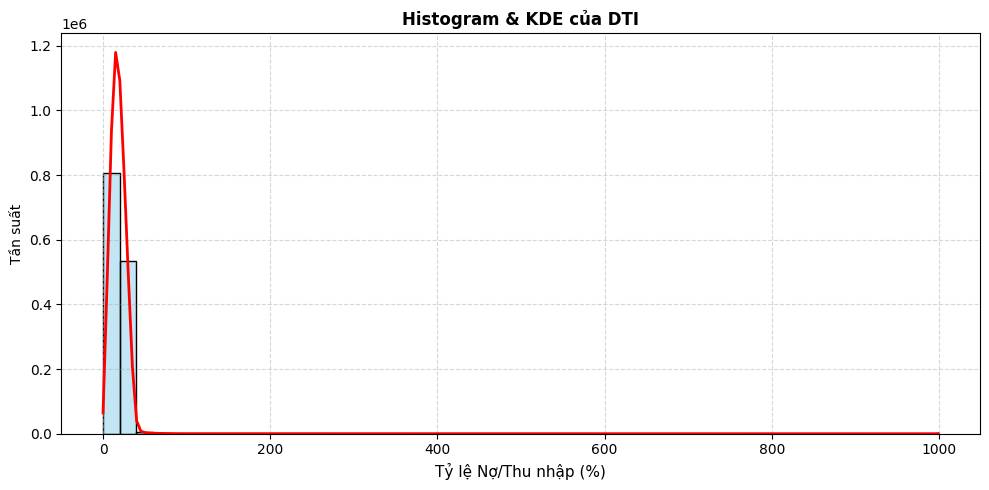

In [15]:
plt.figure(figsize=(10, 5))
ax = sns.histplot(df['dti_n'], kde=True, bins=50, color='#87CEEB')

if ax.lines:
    ax.lines[0].set_color('red')
    ax.lines[0].set_linewidth(2)

plt.title('Histogram & KDE của DTI', fontsize=12, fontweight='bold')
plt.xlabel('Tỷ lệ Nợ/Thu nhập (%)', fontsize=11)
plt.ylabel('Tần suất', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- Phân phối **bị dồn nén cực kỳ chặt** ở góc bên trái (phần lớn tập trung dưới $30\%$), trong khi trục hoành kéo dài một cách bất thường đến tận $1000\%$.

**Biểu đồ Boxplot**

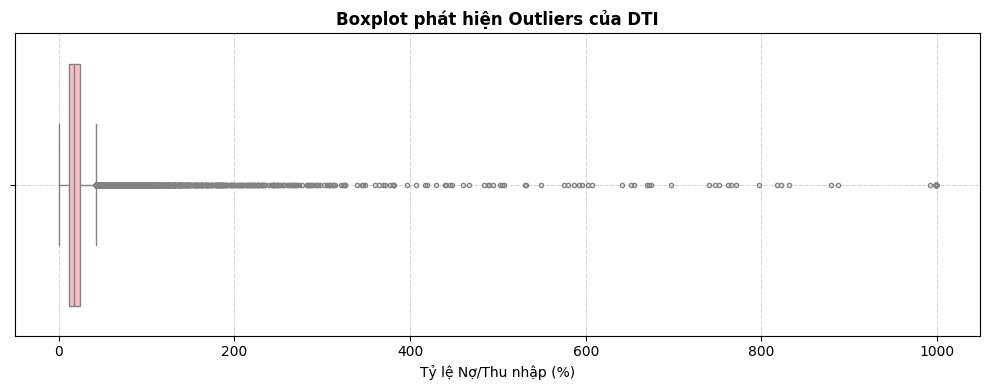

In [16]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['dti_n'], color='#FFB6C1', fliersize=3)
plt.title('Boxplot phát hiện Outliers của DTI', fontsize=12, fontweight='bold')
plt.xlabel('Tỷ lệ Nợ/Thu nhập (%)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Nhận xét:**

- Hộp phân phối chính nằm **rất nhỏ gọn** gần sát mức $0–25\%$, nhưng xuất hiện **một vệt dài dằng dặc** các điểm ngoại lai kéo dài tít sang phải, chạm ngưỡng giới hạn $1000\%$ (tương ứng với giá trị lỗi $999.0$ trong thống kê mô tả).

- Boxplot ghi nhận phần râu ($whisker$) bên phải kéo dài bởi các hồ sơ có tỷ lệ $DTI$ quá lớn (vượt $40\%$). Đây là tệp khách hàng đang phải trích tỷ lệ lớn thu nhập để trả các khoản nợ cũ, mang rủi ro tiềm ẩn cao nhất cho việc vỡ nợ ($Default$).

### Phân phối các biến phân loại ($Categorical Features$)

#### 1. Phân phối biến Kinh nghiệm vay ($experience\_c$)

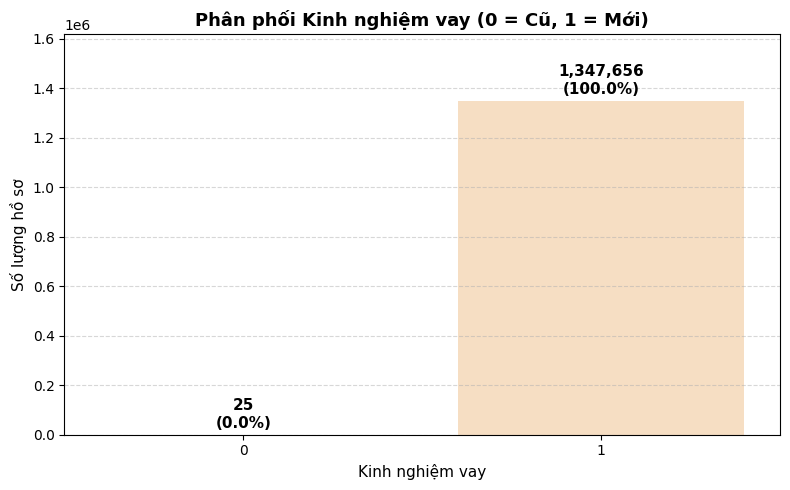

In [17]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x='experience_c', palette=['#FFFFBA', '#FFDFBA'])

total = len(df)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height):,}\n({height/total*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.title('Phân phối Kinh nghiệm vay (0 = Cũ, 1 = Mới)', fontsize=13, fontweight='bold')
plt.xlabel('Kinh nghiệm vay', fontsize=11)
plt.ylabel('Số lượng hồ sơ', fontsize=11)
plt.ylim(0, df['experience_c'].value_counts().max() * 1.2)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

- Khách hàng mới (1): Chiếm gần như toàn bộ tập dữ liệu với 1,347,656 hồ sơ (100.0%).   

- Khách hàng cũ (0): Chỉ có vỏn vẹn 25 hồ sơ (0.0%).

**Nhận xét biến $experience\_c$:**

- **Phân bổ:** Dữ liệu phân hóa thành 2 nhóm rõ rệt là khách hàng đã từng vay (0) và khách hàng mới (1). *(Tùy thuộc vào số liệu hiển thị trên biểu đồ để xem nhóm nào áp đảo hơn).*

- **Ý nghĩa:** Kinh nghiệm vay là một yếu tố quan trọng trong việc chấm điểm tín dụng. Nhóm khách hàng cũ thường có lịch sử tín dụng lưu trên hệ thống rõ ràng hơn, giúp nền tảng đánh giá rủi ro chính xác hơn so với nhóm khách hàng mới tiếp cận.

#### 2. Phân phối biến Tình trạng sở hữu nhà ($home\_ownership\_n$)

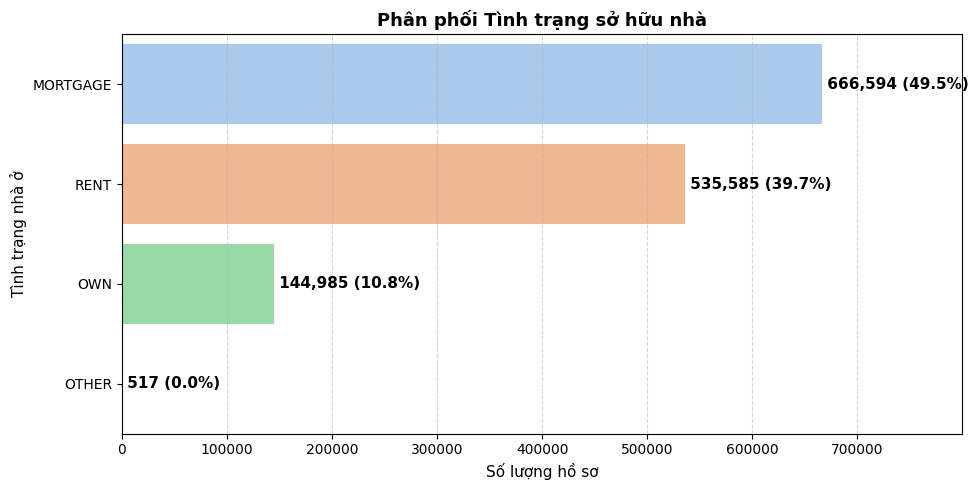

In [18]:
plt.figure(figsize=(10, 5))
order = df['home_ownership_n'].value_counts().index

ax = sns.countplot(data=df, y='home_ownership_n', order=order, palette='pastel')

total = len(df)
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f' {int(width):,} ({width/total*100:.1f}%)',
                (width, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=11, fontweight='bold')

plt.title('Phân phối Tình trạng sở hữu nhà', fontsize=13, fontweight='bold')
plt.xlabel('Số lượng hồ sơ', fontsize=11)
plt.ylabel('Tình trạng nhà ở', fontsize=11)
plt.xlim(0, df['home_ownership_n'].value_counts().max() * 1.2) # Mở rộng trục X
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

- **MORTGAGE (Thế chấp):** Chiếm tỷ trọng lớn nhất với **666,594** hồ sơ ($49.5\%$).   

- **RENT (Thuê nhà):** Đứng ở vị trí thứ hai với **535,585** hồ sơ ($39.7\$%).   

- **OWN (Sở hữu nhà riêng):** Chiếm **144,985** hồ sơ ($10.8\$%).   

- **OTHER (Khác):** Chiếm số lượng **cực kỳ ít**, không đáng kể (**517** hồ sơ, chiếm $0.0\%$).

**Nhận xét biến $home\_ownership\_n$:**

- **Phân bổ:** Đại đa số hồ sơ tập trung ở hai nhóm chính là *Mortgage* (Đang thế chấp trả góp nhà) và *Rent* (Thuê nhà). Nhóm *Own* (Sở hữu nhà hoàn toàn) thường chiếm tỷ lệ nhỏ nhất.

- **Ý nghĩa:** Phân bố này phản ánh đúng thực trạng tài chính của tệp khách hàng tìm đến kênh vay tín chấp: họ thường chưa có tài sản tích lũy lớn để thế chấp trực tiếp, hoặc đang phải gánh các nghĩa vụ tài chính định kỳ khá nặng nề.

#### 3. Phân phối biến Mục đích vay ($purpose$)

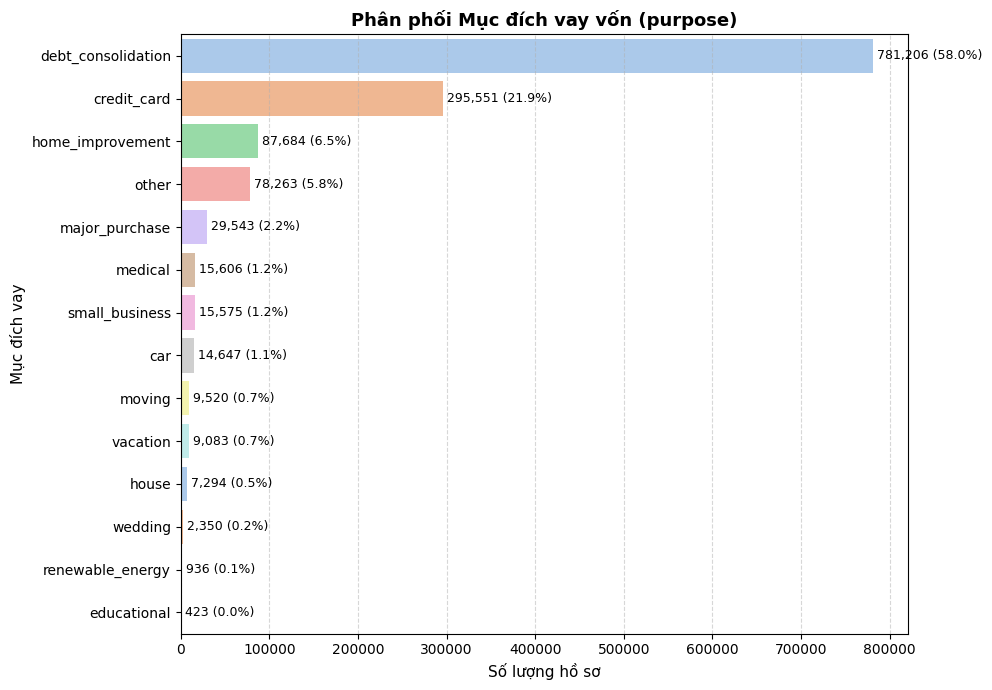

In [19]:
plt.figure(figsize=(10, 7))
order = df['purpose'].value_counts().index
ax = sns.countplot(data=df, y='purpose', order=order, palette='pastel')

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f' {int(width):,} ({width/total*100:.1f}%)',
                (width, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=9)

plt.title('Phân phối Mục đích vay vốn (purpose)', fontsize=13, fontweight='bold')
plt.xlabel('Số lượng hồ sơ', fontsize=11)
plt.ylabel('Mục đích vay', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

- Debt Consolidation (Tái cơ cấu nợ): Chiếm ưu thế áp đảo với 781,206 hồ sơ (58.0%), cho thấy đa số người vay sử dụng vốn để gộp các khoản nợ lại.   

- Credit Card (Thanh toán thẻ tín dụng): Đứng thứ hai với 295,551 hồ sơ (21.9%).   

- Các mục đích khác: Các nhóm như sửa nhà (home_improvement, 6.5%), chi tiêu khác (other, 5.8%) và mua sắm lớn (major_purchase, 2.2%) chiếm phần tỷ trọng nhỏ hơn. Các mục đích còn lại chiếm tỷ lệ rất thấp từ dưới 1% đến 1.2%.

**Nhận xét biến $purpose$:**

- **Đặc trưng:** Mục đích vay áp đảo hoàn toàn là *debt_consolidation* (gộp các khoản nợ) và *credit_card* (thanh toán dư nợ thẻ tín dụng).

- **Ý nghĩa:** Khách hàng vay vốn chủ yếu nhằm mục đích tái cơ cấu các khoản nợ có lãi suất cao thành một khoản vay duy nhất, thay vì phục vụ chi tiêu cá nhân ngắn hạn.

#### 4. Phân phối biến Thâm niên công tác ($emp\_length$)

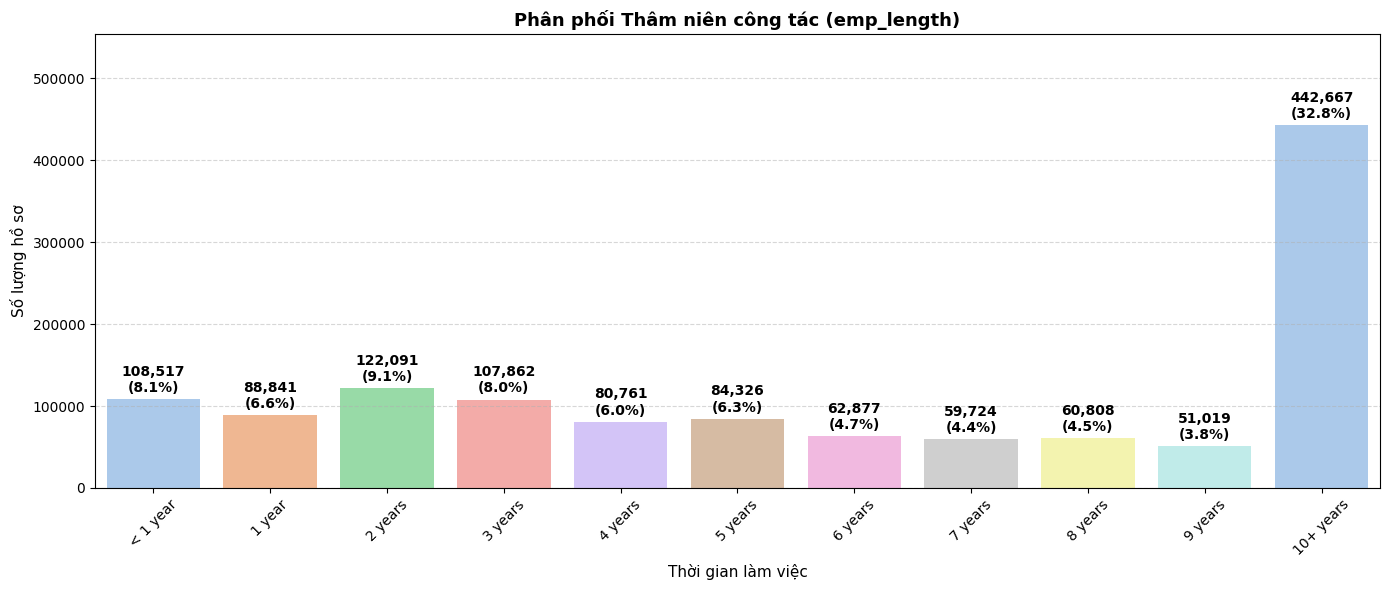

In [20]:
plt.figure(figsize=(14, 6))

emp_order = ['< 1 year', '1 year', '2 years', '3 years', '4 years',
             '5 years', '6 years', '7 years', '8 years', '9 years', '10+ years']

ax = sns.countplot(data=df, x='emp_length', order=emp_order, palette='pastel')

total = len(df)
for p in ax.patches:
    height = p.get_height()
    if pd.notnull(height) and height > 0:
        ax.annotate(f'{int(height):,}\n({height/total*100:.1f}%)',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.title('Phân phối Thâm niên công tác (emp_length)', fontsize=13, fontweight='bold')
plt.xlabel('Thời gian làm việc', fontsize=11)
plt.ylabel('Số lượng hồ sơ', fontsize=11)

plt.xticks(rotation=45)
plt.ylim(0, df['emp_length'].value_counts().max() * 1.25)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Nhận xét biến $emp\_length$:**

- **Phân bổ:** Khi quan sát theo trục thời gian tuyến tính, ta thấy dữ liệu tập trung cực kỳ đông đảo ở nhóm khách hàng có thâm niên trên 10 năm (`10+ years`). Các mốc thời gian còn lại (từ dưới 1 năm đến 9 năm) có sự phân bổ tương đối đồng đều hơn.

- **Ý nghĩa:** Biểu đồ cho thấy tệp khách hàng vay vốn chủ yếu là những người đã đi làm lâu năm và có công việc ổn định. Thâm niên công tác là một biến quan trọng: nhóm khách hàng làm việc càng lâu thường có dòng tiền vững chắc hơn, giúp mạng MLP đánh giá rủi ro vỡ nợ thấp hơn so với nhóm nhảy việc hoặc mới đi làm.

## 6. Tiền xử lý dữ liệu (Data Preprocessing)

Quá trình tiền xử lý sẽ được thực hiện tuần tự qua các bước thực tế sau:

1. **Tách biến định danh và loại bỏ cột nhiễu**
   * Lưu trữ riêng cột `id` để phục vụ tra cứu sau này.
   * Loại bỏ các cột không mang ý nghĩa dự đoán hoặc chứa quá nhiều giá trị nhiễu: `desc`, `zip_code`, `addr_state`, `title`.

2. **Xử lý đặc trưng thời gian**
   * Chuyển đổi cột mốc thời gian phát hành khoản vay (`issue_d`) để trích xuất thành hai biến số lượng: Tháng (`issue_month`) và Năm (`issue_year`).

3. **Chuyển đổi dạng số cho thâm niên công tác**
   * Ánh xạ (`Mapping`) biến chuỗi `emp_length` sang giá trị số nguyên (ví dụ: `< 1 year -> 0`, `10+ years -> 10`).

4. **Xử lý ngoại lệ và biến đổi phân phối**
   * Áp dụng giới hạn trần (`Capping`) cho tỷ lệ nợ trên thu nhập `dti_n` để loại bỏ các giá trị cực đoan.
   * Thực hiện `Log-transform` cho thu nhập (`revenue_log = np.log1p(revenue)`) để làm mượt phân phối dữ liệu.

5. **Chia tập dữ liệu ($Stratified$ $Train$/$Test Split$)**
   * Phân tách dữ liệu thành tập huấn luyện và kiểm tra với tỷ lệ `70/15/15` (hoặc tỷ lệ tương ứng theo cấu hình), sử dụng tham số phân tầng (`stratified split`) theo biến `target` để giữ nguyên tỷ lệ mất cân bằng nhãn nợ xấu.

6. **Xử lý dữ liệu khuyết thiếu ($Missing$ $Imputation$ - Đảm bảo không Leakage)**
   * Tính toán giá trị Trung vị (`Median`) chỉ dựa trên tập huấn luyện (`Train Set`).
   * Điền các giá trị `NaN` bằng giá trị `Median` này cho toàn bộ các phần của tập dữ liệu để tránh rò rỉ thông tin từ tập kiểm thử.

7. **Mã hóa biến phân loại ($Categorical$ $Encoding$)**
   * Áp dụng One-Hot Encoding (`pd.get_dummies` với `drop_first=True`) cho các biến phân loại danh mục: `purpose` và `home_ownership_n`.

8. **Chuẩn hóa dữ liệu & Lưu trữ Artifacts**
   * Khởi tạo `StandardScaler()`.
   * Thực hiện `.fit_transform()` trên tập `Train`, và chỉ dùng `.transform()` trên tập `Validation/Test`.
   * Lưu object `scaler` và danh sách tên đặc trưng vào thư mục `models/` bằng `joblib`.

### 1.1. Tách biến định danh (ID)
Biến `id` không mang giá trị dự đoán và có thể gây nhiễu cho mạng MLP. Ta sẽ tách biến này ra khỏi tập dữ liệu chính và lưu trữ riêng để phục vụ cho việc đối chiếu, truy xuất hồ sơ sau này nếu cần.

In [21]:
# 1.1. Tách biến định danh
loan_ids = df['id'].copy()

# 1.2. Loại bỏ các biến không sử dụng
cols_to_drop = ['id', 'desc', 'zip_code', 'addr_state', 'title']

df = df.drop(columns=cols_to_drop, errors='raise')

print("Kích thước dữ liệu sau khi loại bỏ biến:", df.shape)
print("Số lượng ID được lưu:", len(loan_ids))

assert len(loan_ids) == len(df)
assert df.index.equals(loan_ids.index)

Kích thước dữ liệu sau khi loại bỏ biến: (1347681, 10)
Số lượng ID được lưu: 1347681


**Nhận xét:**
- Tách id riêng là hợp lý vì đây là biến định danh, không nên đưa vào MLP.
- Loại bỏ desc, zip_code, addr_state, title phù hợp với phạm vi mô hình hiện tại.
- Không nên xóa id khỏi hệ thống lưu trữ vì sau này cần truy xuất hồ sơ và đối chiếu dự đoán.

### 2. Trích xuất đặc trưng Thời gian ($Datetime Processing$)
Mạng MLP không thể đọc trực tiếp định dạng ngày tháng. Ta sẽ chuyển đổi cột `issue_d` sang kiểu Datetime, sau đó trích xuất riêng biệt đặc trưng `Tháng` (có thể mang tính chu kỳ mùa vụ) và `Năm` (xu hướng vĩ mô), cuối cùng loại bỏ cột gốc.

In [22]:
# 2. Trích xuất đặc trưng thời gian
df['issue_d'] = pd.to_datetime(
    df['issue_d'],
    errors='coerce'
)

df['issue_month'] = df['issue_d'].dt.month
df['issue_year'] = df['issue_d'].dt.year

df = df.drop(columns=['issue_d'])

display(df[['issue_month', 'issue_year']].head())

print("Số giá trị thiếu issue_month:",
      df['issue_month'].isna().sum())

print("Số giá trị thiếu issue_year:",
      df['issue_year'].isna().sum())

,issue_month,issue_year
0,12,2015
1,12,2015
2,12,2015
3,12,2015
4,12,2015


Số giá trị thiếu issue_month: 0
Số giá trị thiếu issue_year: 0


**Nhận xét:**

- Cách trích xuất tháng và năm phù hợp. Tuy nhiên, nếu có giá trị ngày tháng không hợp lệ, pd.to_datetime() mặc định có thể phát sinh lỗi.

### 3. Chuyển đổi biến Thâm niên công tác ($emp\_length$) sang dạng số
Biến `emp_length` đang ở dạng chuỗi (String) như `10+ years`, `< 1 year`. Ta sẽ dùng kỹ thuật Ánh xạ (Mapping) để chuyển đổi chúng thành các giá trị số nguyên từ 0 đến 10, giúp mô hình hiểu được tính thứ bậc (Ordinal) của thời gian làm việc.

In [23]:
# 3. Chuyển đổi emp_length sang dạng số

emp_map = {
    'NI': np.nan,
    '< 1 year': 0,
    '1 year': 1,
    '2 years': 2,
    '3 years': 3,
    '4 years': 4,
    '5 years': 5,
    '6 years': 6,
    '7 years': 7,
    '8 years': 8,
    '9 years': 9,
    '10+ years': 10
}

df['emp_length_num'] = df['emp_length'].map(emp_map)

# Kiểm tra các giá trị không được ánh xạ
unmapped = df.loc[
    df['emp_length_num'].isna() &
    df['emp_length'].notna(),
    'emp_length'
].unique()

print("Các giá trị chưa được ánh xạ:", unmapped)

df = df.drop(columns=['emp_length'])

print("\nPhân phối emp_length_num:")
display(df['emp_length_num'].value_counts(dropna=False).sort_index())

Các giá trị chưa được ánh xạ: ['NI']

Phân phối emp_length_num:


emp_length_num
0.0     108517
1.0      88841
2.0     122091
3.0     107862
4.0      80761
5.0      84326
6.0      62877
7.0      59724
8.0      60808
9.0      51019
10.0    442667
NaN      78188
Name: count, dtype: int64

### 4. Xử lý ngoại lệ và biến đổi phân phối
Biến $dti\_n$ có một số giá trị kéo dài đột biến ở phần đuôi. Để tránh làm xô lệch trọng số của mạng MLP, ta dùng phương pháp **Capping/Winsorizing**: giới hạn trần các giá trị vượt quá bách phân vị thứ 99 (99th percentile) bằng chính mức giá trị tại P99 đó.

Số revenue âm: 0
Số revenue bằng 0: 0
Số revenue thiếu: 0


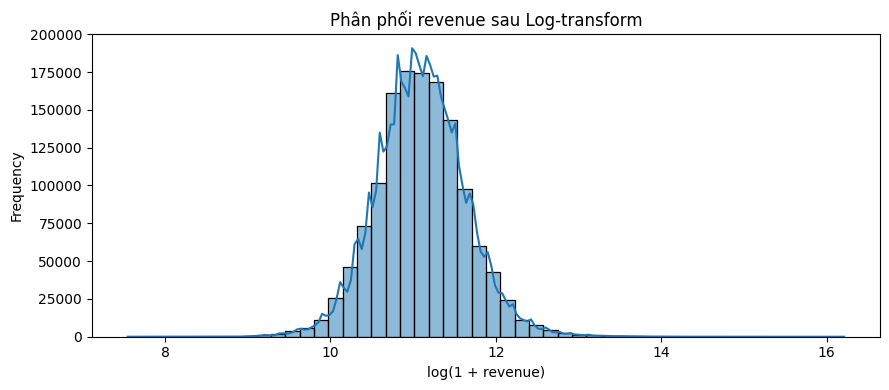

In [24]:
# Kiểm tra revenue
print("Số revenue âm:",
      (df['revenue'] < 0).sum())

print("Số revenue bằng 0:",
      (df['revenue'] == 0).sum())

print("Số revenue thiếu:",
      df['revenue'].isna().sum())

# Xử lý giá trị revenue không hợp lệ
df.loc[df['revenue'] < 0, 'revenue'] = np.nan

# Log-transform
df['revenue_log'] = np.log1p(df['revenue'])


df = df.drop(columns=['revenue'])


plt.figure(figsize=(9, 4))

sns.histplot(
    df['revenue_log'].dropna(),
    kde=True,
    bins=50
)

plt.title('Phân phối revenue sau Log-transform')
plt.xlabel('log(1 + revenue)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### 5. Chia tập dữ liệu ($Stratified$, $TrainValidation$, $Test Split$)

In [25]:
target_col = 'Default'

y = df[target_col].astype(int).copy()

X = df.drop(columns=[target_col]).copy()

train_idx, temp_idx = train_test_split(
    df.index,
    test_size=0.30,
    random_state=42,
    stratify=y
)


val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=y.loc[temp_idx]
)


X_train = X.loc[train_idx].copy()
X_val = X.loc[val_idx].copy()
X_test = X.loc[test_idx].copy()

y_train = y.loc[train_idx].copy()
y_val = y.loc[val_idx].copy()
y_test = y.loc[test_idx].copy()

id_train = loan_ids.loc[train_idx].copy()
id_val = loan_ids.loc[val_idx].copy()
id_test = loan_ids.loc[test_idx].copy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


print("\nTỷ lệ Default trong từng tập:")
for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}:")
    print(target.value_counts(normalize=True).sort_index())


Train: (943376, 10)
Validation: (202152, 10)
Test: (202153, 10)

Tỷ lệ Default trong từng tập:

Train:
Default
0    0.800213
1    0.199787
Name: proportion, dtype: float64

Validation:
Default
0    0.800215
1    0.199785
Name: proportion, dtype: float64

Test:
Default
0    0.800211
1    0.199789
Name: proportion, dtype: float64


**Nhận Xét:**
- Train (70%): Sử dụng để xây dựng mô hình và học các tham số tiền xử lý dữ liệu.
- Validation (15%): Sử dụng để đánh giá trong quá trình huấn luyện và điều chỉnh siêu tham số.
- Test (15%): Chỉ sử dụng để đánh giá hiệu quả cuối cùng của mô hình sau khi hoàn tất lựa chọn mô hình.

### 6. Xử lý dữ liệu khuyết thiếu ($Missing Imputation$ & $Campping$):
Biến `revenue` bị lệch phải nghiêm trọng do các hồ sơ khai báo thu nhập hàng triệu đô la. Ta sẽ sử dụng phép biến đổi Logarit tự nhiên (`np.log1p` - $log(1+x)$ để tránh lỗi với giá trị 0) nhằm thu hẹp thang đo và kéo phân phối về gần chuẩn (Normal Distribution) hơn.

In [26]:
p99_dti = X_train['dti_n'].quantile(0.99)

print("Ngưỡng P99 của dti_n:", p99_dti)

# Áp dụng cùng một ngưỡng cho cả ba tập
X_train['dti_n'] = X_train['dti_n'].clip(upper=p99_dti)
X_val['dti_n'] = X_val['dti_n'].clip(upper=p99_dti)
X_test['dti_n'] = X_test['dti_n'].clip(upper=p99_dti)

print("\nKiểm tra giá trị lớn nhất sau Capping:")
print("Train:", X_train['dti_n'].max())
print("Validation:", X_val['dti_n'].max())
print("Test:", X_test['dti_n'].max())


Ngưỡng P99 của dti_n: 38.46

Kiểm tra giá trị lớn nhất sau Capping:
Train: 38.46
Validation: 38.46
Test: 38.46


In [27]:
for data in [X_train, X_val, X_test]:
    data.replace([np.inf, -np.inf], np.nan, inplace=True)


categorical_cols = ['home_ownership_n', 'purpose']

numeric_cols = [
    col for col in X_train.columns
    if col not in categorical_cols
    and pd.api.types.is_numeric_dtype(X_train[col])
]


other_cols = [
    col for col in X_train.columns
    if col not in numeric_cols + categorical_cols
]

if other_cols:
    raise ValueError(
        f"Cần xác định cách xử lý các cột: {other_cols}"
    )


all_missing_num = [
    col for col in numeric_cols
    if X_train[col].isna().all()
]

all_missing_cat = [
    col for col in categorical_cols
    if X_train[col].isna().all()
]

if all_missing_num or all_missing_cat:
    raise ValueError(
        f"Cột số hoàn toàn thiếu: {all_missing_num}; "
        f"Cột phân loại hoàn toàn thiếu: {all_missing_cat}"
    )

numeric_imputer = SimpleImputer(strategy='median')

X_train_num = pd.DataFrame(
    numeric_imputer.fit_transform(X_train[numeric_cols]),
    columns=numeric_cols,
    index=X_train.index
)

X_val_num = pd.DataFrame(
    numeric_imputer.transform(X_val[numeric_cols]),
    columns=numeric_cols,
    index=X_val.index
)

X_test_num = pd.DataFrame(
    numeric_imputer.transform(X_test[numeric_cols]),
    columns=numeric_cols,
    index=X_test.index
)

# Computation cho biến phân loại bằng Mode
categorical_imputer = SimpleImputer(strategy='most_frequent')

X_train_cat = pd.DataFrame(
    categorical_imputer.fit_transform(X_train[categorical_cols]),
    columns=categorical_cols,
    index=X_train.index
)

X_val_cat = pd.DataFrame(
    categorical_imputer.transform(X_val[categorical_cols]),
    columns=categorical_cols,
    index=X_val.index
)

X_test_cat = pd.DataFrame(
    categorical_imputer.transform(X_test[categorical_cols]),
    columns=categorical_cols,
    index=X_test.index
)

print("Số lượng giá trị thiếu sau Imputation:")
print("Train:", X_train_num.isna().sum().sum()
      + X_train_cat.isna().sum().sum())
print("Validation:", X_val_num.isna().sum().sum()
      + X_val_cat.isna().sum().sum())
print("Test:", X_test_num.isna().sum().sum()
      + X_test_cat.isna().sum().sum())


Số lượng giá trị thiếu sau Imputation:
Train: 0
Validation: 0
Test: 0


### 7. Mã hóa các biến phân loại (Categorical Encoding)
Mạng Nơ-ron yêu cầu toàn bộ đầu vào phải là số. Các biến phân loại không có tính thứ bậc (Nominal Categories) như `purpose` và `home_ownership_n` sẽ được mã hóa bằng kỹ thuật **One-Hot Encoding** (tạo các cột biến giả nhị phân 0/1).

In [28]:
try:
    encoder = OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False,
        dtype=np.float32
    )
except TypeError:
    encoder = OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse=False,
        dtype=np.float32
    )

X_train_cat_encoded = encoder.fit_transform(X_train_cat)

X_val_cat_encoded = encoder.transform(X_val_cat)
X_test_cat_encoded = encoder.transform(X_test_cat)


encoded_cat_names = encoder.get_feature_names_out(
    categorical_cols
).tolist()


print("Train categorical:", X_train_cat_encoded.shape)
print("Validation categorical:", X_val_cat_encoded.shape)
print("Test categorical:", X_test_cat_encoded.shape)

print("\nTên các đặc trưng sau mã hóa:")
print(encoded_cat_names)


assert X_train_cat_encoded.shape[1] == X_val_cat_encoded.shape[1]
assert X_train_cat_encoded.shape[1] == X_test_cat_encoded.shape[1]



Train categorical: (943376, 16)
Validation categorical: (202152, 16)
Test categorical: (202153, 16)

Tên các đặc trưng sau mã hóa:
['home_ownership_n_OTHER', 'home_ownership_n_OWN', 'home_ownership_n_RENT', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_house', 'purpose_major_purchase', 'purpose_medical', 'purpose_moving', 'purpose_other', 'purpose_renewable_energy', 'purpose_small_business', 'purpose_vacation', 'purpose_wedding']


### 8. Chuẩn hóa dữ liệu & Lưu trữ Artifacts:

In [29]:
scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(X_train_num)

X_val_num_scaled = scaler.transform(X_val_num)
X_test_num_scaled = scaler.transform(X_test_num)

print("Numeric Train:", X_train_num_scaled.shape)
print("Numeric Validation:", X_val_num_scaled.shape)
print("Numeric Test:", X_test_num_scaled.shape)


Numeric Train: (943376, 8)
Numeric Validation: (202152, 8)
Numeric Test: (202153, 8)


In [30]:

X_train_final = np.hstack([
    X_train_num_scaled,
    X_train_cat_encoded
]).astype(np.float32)

X_val_final = np.hstack([
    X_val_num_scaled,
    X_val_cat_encoded
]).astype(np.float32)

X_test_final = np.hstack([
    X_test_num_scaled,
    X_test_cat_encoded
]).astype(np.float32)

feature_names = numeric_cols + encoded_cat_names


print("Final Train:", X_train_final.shape)
print("Final Validation:", X_val_final.shape)
print("Final Test:", X_test_final.shape)

print("Tổng số đặc trưng:", len(feature_names))


assert np.isfinite(X_train_final).all()
assert np.isfinite(X_val_final).all()
assert np.isfinite(X_test_final).all()

assert X_train_final.shape[1] == X_val_final.shape[1]
assert X_train_final.shape[1] == X_test_final.shape[1]
assert X_train_final.shape[1] == len(feature_names)


Final Train: (943376, 24)
Final Validation: (202152, 24)
Final Test: (202153, 24)
Tổng số đặc trưng: 24


In [31]:
# MODULE 1: LƯU PREPROCESSING ARTIFACTS

os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)

joblib.dump(
    scaler,
    "models/scaler.pkl"
)

joblib.dump(
    feature_names,
    "models/feature_columns.pkl"
)

preprocessing_artifacts = {
    "numeric_imputer": numeric_imputer,
    "categorical_imputer": categorical_imputer,
    "encoder": encoder,
    "numeric_cols": numeric_cols,
    "categorical_cols": categorical_cols,
    "encoded_cat_names": encoded_cat_names,
    "feature_names": feature_names,
    "p99_dti": p99_dti
}

joblib.dump(
    preprocessing_artifacts,
    "models/preprocessing_artifacts.pkl"
)



processed_train = pd.DataFrame(
    X_train_final,
    columns=feature_names,
    index=train_idx
)
processed_train["Default"] = y_train
processed_train["Dataset"] = "Train"

processed_val = pd.DataFrame(
    X_val_final,
    columns=feature_names,
    index=val_idx
)
processed_val["Default"] = y_val
processed_val["Dataset"] = "Validation"

processed_test = pd.DataFrame(
    X_test_final,
    columns=feature_names,
    index=test_idx
)
processed_test["Default"] = y_test
processed_test["Dataset"] = "Test"

processed_data = pd.concat([
    processed_train,
    processed_val,
    processed_test
]).sort_index()

processed_data.insert(
    0,
    "loan_id",
    loan_ids.loc[processed_data.index].values
)

# Lưu dữ liệu đã preprocessing
processed_data.to_csv(
    "data/processed_data.csv",
    index=False,
    encoding="utf-8-sig"
)

# Kiểm tra kết quả
print("=" * 50)
print("MODULE 1 - LƯU PREPROCESSING THÀNH CÔNG")
print("=" * 50)

print("\nSố lượng features:", len(feature_names))
print("Train:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

print("\nPhân chia dữ liệu:")
print(processed_data["Dataset"].value_counts())

print("\nDanh sách file đã lưu:")
print("- data/processed_data.csv")
print("- models/scaler.pkl")
print("- models/feature_columns.pkl")
print("- models/preprocessing_artifacts.pkl")

print("\nKích thước processed_data:", processed_data.shape)

MODULE 1 - LƯU PREPROCESSING THÀNH CÔNG

Số lượng features: 24
Train: (943376, 24)
Validation: (202152, 24)
Test: (202153, 24)

Phân chia dữ liệu:
Dataset
Train         943376
Test          202153
Validation    202152
Name: count, dtype: int64

Danh sách file đã lưu:
- data/processed_data.csv
- models/scaler.pkl
- models/feature_columns.pkl
- models/preprocessing_artifacts.pkl

Kích thước processed_data: (1347681, 27)


## Module 2: Baseline & Feature Importance

### 1. Logistic Regression

In [33]:
# 1. Khởi tạo mô hình
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_final, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


### 2. Random Forest Classifier

In [34]:
# 1. Khởi tạo mô hình

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_final, y_train)

print("Random Forest training completed!")

Random Forest training completed!


### 3. Model Evaluation & Comparison

4.1. Tạo hàm đánh giá

In [35]:
def evaluate_model(y_true, y_pred, y_prob, model_name):

    return {
        "Model": model_name,
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Macro-F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    }

4.2. Dự đoán trên Validation

In [36]:
# Logistic Regression
y_val_pred_lr = lr_model.predict(X_val_final)
y_val_prob_lr = lr_model.predict_proba(X_val_final)[:, 1]

# Random Forest
y_val_pred_rf = rf_model.predict(X_val_final)
y_val_prob_rf = rf_model.predict_proba(X_val_final)[:, 1]

# Tổng hợp kết quả
validation_results = pd.DataFrame([
    evaluate_model(
        y_val, y_val_pred_lr, y_val_prob_lr,
        "Logistic Regression"
    ),
    evaluate_model(
        y_val, y_val_pred_rf, y_val_prob_rf,
        "Random Forest"
    )
])

display(
    validation_results.sort_values(
        "ROC-AUC", ascending=False
    )
)

,Model,ROC-AUC,Precision,Recall,Macro-F1
0,Logistic Regression,0.660912,0.553704,0.007403,0.451814
1,Random Forest,0.643201,0.424934,0.039666,0.479424


4.3. Đánh giá trên Test

In [37]:
# Logistic Regression
y_test_pred_lr = lr_model.predict(X_test_final)
y_test_prob_lr = lr_model.predict_proba(X_test_final)[:, 1]

# Random Forest
y_test_pred_rf = rf_model.predict(X_test_final)
y_test_prob_rf = rf_model.predict_proba(X_test_final)[:, 1]

test_results = pd.DataFrame([
    evaluate_model(
        y_test, y_test_pred_lr, y_test_prob_lr,
        "Logistic Regression"
    ),
    evaluate_model(
        y_test, y_test_pred_rf, y_test_prob_rf,
        "Random Forest"
    )
])

display(test_results)

,Model,ROC-AUC,Precision,Recall,Macro-F1
0,Logistic Regression,0.659603,0.491743,0.006636,0.450961
1,Random Forest,0.642342,0.425994,0.040334,0.479979


Lưu hai mô hình và kết quả

In [38]:
# Lưu hai mô hình
joblib.dump(
    lr_model,
    "models/logistic_regression.pkl"
)

joblib.dump(
    rf_model,
    "models/random_forest.pkl"
)

# Lưu kết quả đánh giá
validation_results.to_csv(
    "models/baseline_validation_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

test_results.to_csv(
    "models/baseline_test_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu hai mô hình và kết quả đánh giá!")

Đã lưu hai mô hình và kết quả đánh giá!


In [39]:
# 4. FEATURE IMPORTANCE - RANDOM FOREST


feature_importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

top10_features = importance_df.head(10)

print("TOP 10 FEATURES IMPORTANCE:")
display(top10_features)

top10_features.to_csv(
    "models/top10_feature_importance.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu Top 10 Feature Importance!")


TOP 10 FEATURES IMPORTANCE:


,Feature,Importance
0,dti_n,0.233227
7,revenue_log,0.194490
1,loan_amnt,0.172633
4,issue_month,0.108469
2,fico_n,0.104000
6,emp_length_num,0.082087
5,issue_year,0.059641
10,home_ownership_n_RENT,0.008050
9,home_ownership_n_OWN,0.006945
12,purpose_debt_consolidation,0.006191


Đã lưu Top 10 Feature Importance!


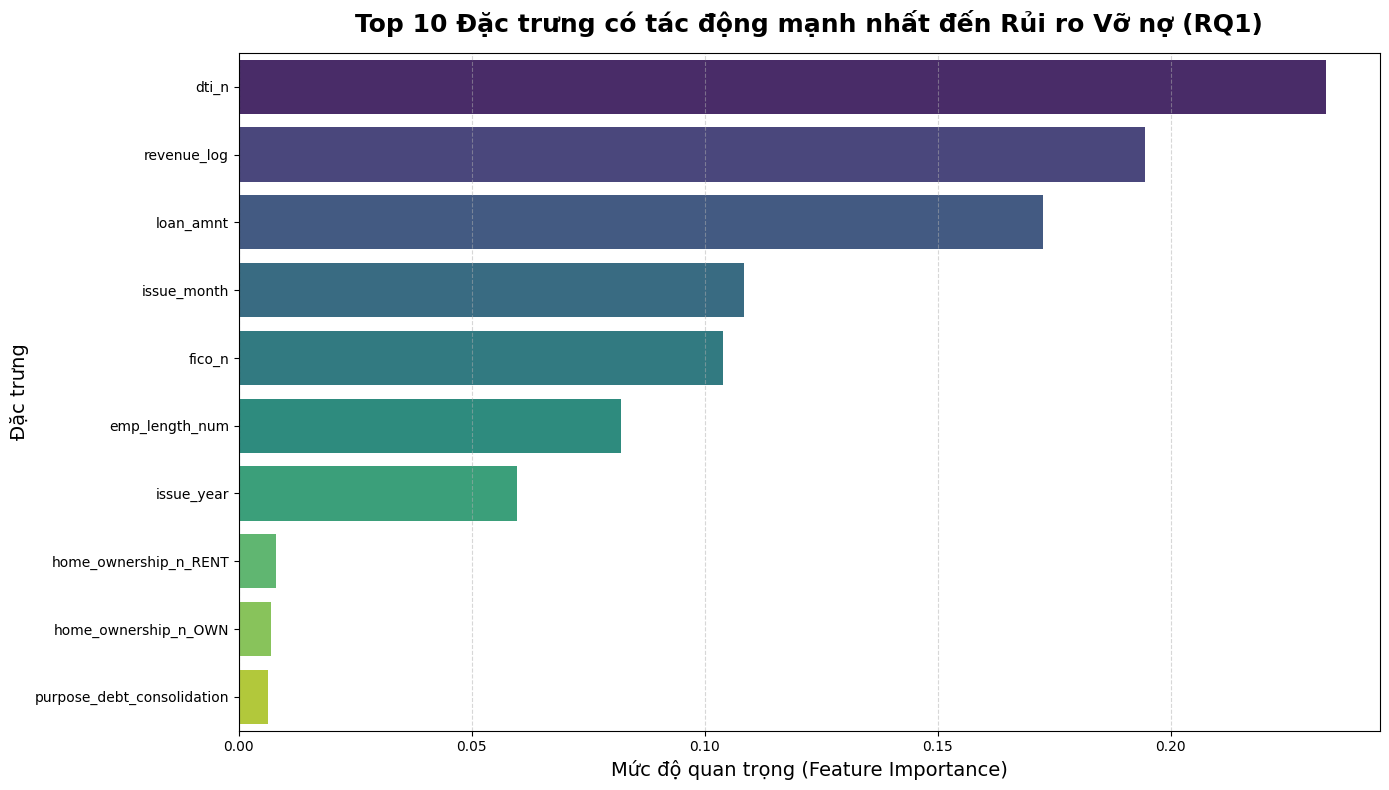

Đã lưu biểu đồ Feature Importance thành công!


In [40]:
# VISUALIZE TOP 10 FEATURE IMPORTANCE

plt.figure(figsize=(14, 8))

sns.barplot(
    data=top10_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title(
    "Top 10 Đặc trưng có tác động mạnh nhất đến Rủi ro Vỡ nợ (RQ1)",
    fontsize=18,
    fontweight="bold",
    pad=15
)

plt.xlabel("Mức độ quan trọng (Feature Importance)", fontsize=14)
plt.ylabel("Đặc trưng", fontsize=14)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

# Lưu biểu đồ
plt.savefig(
    "models/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Đã lưu biểu đồ Feature Importance thành công!")


## Module 3: XÂY DỰNG VÀ HUẤN LUYỆN MÔ HÌNH DEEP LEARNING

Mục tiêu: Thiết kế kiến trúc mạng nơ-ron sâu (Residual MLP) bằng PyTorch từ các tầng tuyến tính cơ bản (nn.Linear), tuân thủ nghiêm ngặt quy trình huấn luyện chuẩn học thuật:

1. Tự khởi tạo trọng số (Kaiming / He Initialization): Giữ phương sai ổn định qua các tầng, tránh rơi vào vùng bão hòa ngay từ vòng học đầu tiên.

2. Xử lý mất cân bằng dữ liệu (pos_weight): Tự tính tỷ lệ nhãn và truyền vào hàm BCEWithLogitsLoss để phạt nặng khi đoán sai khách hàng vỡ nợ.

3. Sanity Check trên tập siêu nhỏ (5 mẫu): Kiểm chứng luồng lan truyền xuôi/ngược (Forward/Backward) trước khi huấn luyện trên toàn bộ dữ liệu lớn.

4. Kiểm soát dòng học: Tích hợp Gradient Clipping chống bùng nổ số liệu (NaN), lập lịch tốc độ học Cosine Annealing và Early Stopping chống Overfitting.

In [46]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import copy
import os

# Thiết lập seed cố định để đảm bảo tính tái lập (Reproducibility)
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
os.makedirs('models', exist_ok=True)
print("Đã khởi tạo môi trường, thiết lập seed=42 và tạo thư mục 'models/' thành công!")

Đã khởi tạo môi trường, thiết lập seed=42 và tạo thư mục 'models/' thành công!


### Đóng gói Dữ liệu đầu vào (PyTorch Dataset)

- **Đầu vào:** Các mảng đặc trưng X_train_final, X_val_final, X_test_final (định dạng np.float32 từ Module 1) và vector nhãn mục tiêu y (Default).   

- **Lý do kỹ thuật:** Ép kiểu toàn bộ tensor về torch.float32 giúp đồng bộ kiểu dữ liệu với trọng số của mạng nơ-ron, tối ưu tốc độ tính toán ma trận trên GPU/CPU và tránh lỗi xung đột kiểu dữ liệu khi tính hàm mất mát nhị phân.

In [47]:
class CreditRiskDataset(Dataset):
    """
    Chuyển đổi mảng numpy từ Module 1 thành PyTorch Tensors để nạp theo từng mini-batch.
    """
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y.values if hasattr(y, 'values') else y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

### Kiến trúc Mạng Residual MLP & Khởi tạo Trọng số Kaiming (He Init)

- Cải tiến kiến trúc (Skip Connection): Thay vì xếp chồng các lớp tuyến tính thuần túy dễ gây triệt tiêu đạo hàm (Vanishing Gradient), mô hình bổ sung kết nối tắt $\text{Output} = \text{SiLU}(x + \mathcal{F}(x))$. Nhờ đó tín hiệu gốc được bảo toàn xuyên suốt các tầng sâu, giúp mô hình nắm bắt tốt các quan hệ phi tuyến tính phức tạp của dữ liệu tín dụng.

- Khởi tạo trọng số Kaiming Normal: Trọng số $W$ được rút mẫu từ phân phối chuẩn $\mathcal{N}(0, \sigma^2)$ với độ lệch chuẩn:
$$\sigma = \sqrt{\frac{2}{n_{\text{in}}}}$$

- Ví dụ tính tay minh họa: Với đầu vào từ Module 1 giả sử có $n_{\text{in}} = 32$ đặc trưng:
$$\sigma = \sqrt{\frac{2}{32}} = \sqrt{\frac{1}{16}} = \mathbf{0.25}, \quad b = \mathbf{0.0}$$

Nhờ khởi tạo độ lệch chuẩn bằng $0.25$, phương sai tín hiệu qua 32 chiều được giữ ổn định quanh mức $1.0$, ngăn chặn tình trạng bùng nổ hoặc bão hòa hàm kích hoạt ngay tại Epoch đầu tiên.

In [48]:
class ResidualBlock(nn.Module):
    """
    Khối Residual Block với kết nối tắt (Skip Connection) giúp chống triệt tiêu gradient.
    """
    def __init__(self, dim, dropout_rate=0.3):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(dim, dim),
            nn.BatchNorm1d(dim),
            nn.SiLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(dim, dim),
            nn.BatchNorm1d(dim)
        )
        self.activation = nn.SiLU()

    def forward(self, x):
        return self.activation(x + self.block(x))


class AdvancedResidualMLP(nn.Module):
    """
    Kiến trúc Residual MLP tự thiết kế, hỗ trợ bật/tắt Skip Connection để phục vụ Ablation Study (RQ3).
    """
    def __init__(self, input_dim, hidden_dim=128, num_blocks=2, dropout_rate=0.3, use_residual=True):
        super().__init__()
        self.use_residual = use_residual
        
        self.input_layer = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout_rate)
        )
        
        self.blocks = nn.ModuleList([
            ResidualBlock(hidden_dim, dropout_rate) for _ in range(num_blocks)
        ])
        
        self.output_layer = nn.Linear(hidden_dim, 1) # Xuất logits thô
        
        # Gọi hàm tự khởi tạo trọng số Kaiming Normal
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1.0)
                nn.init.constant_(m.bias, 0.0)

    def forward(self, x):
        out = self.input_layer(x)
        for block in self.blocks:
            if self.use_residual:
                out = block(out) # Mô hình đầy đủ (Có Skip Connection)
            else:
                out = block.block(out) # Biến thể Ablation (Bỏ Skip Connection)
        return self.output_layer(out).squeeze(-1)

### Kiểm tra Kỹ thuật: Sanity Check trên 5 Mẫu Dữ liệu

**Nguyên lý:** Trước khi huấn luyện trên hàng trăm nghìn hồ sơ, ta tắt Dropout (dropout_rate=0.0) và ép mô hình học thuộc lòng **đúng 5 mẫu dữ liệu đầu tiên.**

Tính tay quá trình hội tụ (với 1 mẫu $y=1$, $\text{lr}=0.5$):

- Bước 0: $z_0 = 0.0 \Rightarrow \hat{y}_0 = \sigma(0.0) = 0.5 \Rightarrow \text{Loss}_0 = -\ln(0.5) = \mathbf{0.6931}$.

- Bước 1: Đạo hàm $\frac{\partial \mathcal{L}}{\partial z} = 0.5 - 1 = -0.5 \Rightarrow z_1 = 0.25 \Rightarrow \hat{y}_1 = 0.5622 \Rightarrow \text{Loss}_1 = \mathbf{0.5759}$.

- Sau 50 bước: $z_{50} \approx 6.9 \Rightarrow \hat{y}_{50} \approx 0.999 \Rightarrow \text{Loss}_{50} = -\ln(0.999) = \mathbf{0.0010} \rightarrow 0$.

Nếu Loss hội tụ sát về $0.0$, toàn bộ đồ thị tính toán lan truyền xuôi/ngược được xác nhận không có lỗi logic.

In [49]:
def run_sanity_check(input_dim, X_train, y_train, device):
    print("\n--- [SANITY CHECK] Kiểm tra luồng gradient trên 5 mẫu dữ liệu đầu tiên ---")
    small_ds = CreditRiskDataset(X_train[:5], y_train[:5])
    small_loader = DataLoader(small_ds, batch_size=5, shuffle=False)
    
    model = AdvancedResidualMLP(input_dim=input_dim, dropout_rate=0.0).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.BCEWithLogitsLoss()
    
    model.train()
    for _ in range(50):
        for bx, by in small_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
            
    print(f"-> Sanity Check Loss sau 50 steps: {loss.item():.6f} (Đạt yêu cầu: tiến sát 0.0)")

### Vòng lặp Huấn luyện Chuyên sâu & Kiểm soát Dòng học

1. Trọng số mất cân bằng (pos_weight):

$$\text{pos\_weight} = \frac{N_{\text{negative}}}{N_{\text{positive}}}$$

- Tính tay: Giả sử tập train có $8.000$ mẫu tốt và $2.000$ mẫu vỡ nợ $\Rightarrow \text{pos\_weight} = \frac{8000}{2000} = \mathbf{4.0}$. Với khách hàng vỡ nợ ($y=1$) có $z = 0.5 \Rightarrow \hat{y} = 0.6225$:$$\mathcal{L} = -4.0 \times \ln(0.6225) = \mathbf{1.896} \quad (\text{Gấp 4 lần mức } 0.474 \text{ khi không có trọng số})$$

2. Chống bùng nổ đạo hàm (Gradient Clipping, $\text{max\_norm} = 1.0$):

- Tính tay: Nếu gặp batch nhiễu làm vector gradient bùng nổ thành $g = [3.0, -4.0]$, chuẩn Euclid $\Vert{}g\Vert{}_2 = \sqrt{3^2 + (-4)^2} = \mathbf{5.0} > 1.0$. Hệ thống tự động thu nhỏ:

$$g_{\text{clipped}} = [3.0, -4.0] \times \frac{1.0}{5.0} = \mathbf{[0.6, -0.8]} \quad (\Vert{}g_{\text{clipped}}\Vert{}_2 = 1.0)$$

3. Lập lịch tốc độ học (CosineAnnealingLR):

$$\eta_t = \eta_{\min} + \frac{1}{2}(\eta_{\max} - \eta_{\min})\left(1 + \cos\left(\frac{t}{T_{\max}}\pi\right)\right)$$

- Tính tay ($\eta_{\max}=0.001, \eta_{\min}=0.00001, T_{\max}=20$): Tại $t=0 \Rightarrow \eta_0 = \mathbf{0.00100}$; tại $t=10 \Rightarrow \eta_{10} = \mathbf{0.000505}$; tại $t=20 \Rightarrow \eta_{20} = \mathbf{0.00001}$.

4. Dừng sớm (Early Stopping, patience = 5): Nếu chỉ số Val ROC-AUC không vượt qua kỷ lục cao nhất trong $5$ epoch liên tiếp, vòng lặp tự động ngắt và khôi phục trọng số tốt nhất để chống Overfitting.

In [51]:
def train_deep_learning_model(X_train, y_train, X_val, y_val, config, use_residual=True):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\n[Training] Thiết bị tính toán: {device} | Residual Enabled: {use_residual}")
    
    input_dim = X_train.shape[1]
    
    # Bước 1: Chạy Sanity Check
    run_sanity_check(input_dim, X_train, y_train, device)
    
    # Bước 2: Tạo DataLoaders
    train_loader = DataLoader(CreditRiskDataset(X_train, y_train), batch_size=config['batch_size'], shuffle=True)
    val_loader = DataLoader(CreditRiskDataset(X_val, y_val), batch_size=config['batch_size'] * 2, shuffle=False)
    
    # Bước 3: Khởi tạo mô hình
    model = AdvancedResidualMLP(
        input_dim=input_dim,
        hidden_dim=config['hidden_dim'],
        num_blocks=config['num_blocks'],
        dropout_rate=config['dropout_rate'],
        use_residual=use_residual
    ).to(device)
    
    # Bước 4: Tính trọng số pos_weight chống mất cân bằng dữ liệu
    num_neg = (y_train == 0).sum()
    num_pos = (y_train == 1).sum()
    pos_weight = torch.tensor([num_neg / num_pos], dtype=torch.float32).to(device)
    print(f"-> Trọng số hàm Loss tự tính (pos_weight): {pos_weight.item():.2f}")
    
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    
    # Bước 5: Cấu hình Optimizer (AdamW) & Scheduler (CosineAnnealingLR)
    optimizer = optim.AdamW(model.parameters(), lr=config['learning_rate'], weight_decay=config['weight_decay'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config['epochs'], eta_min=config['min_lr'])
    
    history = {'train_loss': [], 'val_loss': [], 'val_auc': []}
    best_val_auc = 0.0
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0

    print("\n--- BẮT ĐẦU VÒNG LẶP HUẤN LUYỆN ---")
    for epoch in range(config['epochs']):
        # --- TRAIN MODE ---
        model.train()
        train_loss_accum = 0.0
        
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            
            logits = model(bx)
            loss = criterion(logits, by)
            
            if torch.isnan(loss):
                raise ValueError("Lỗi: Phát hiện giá trị NaN trong Loss!")
                
            loss.backward()
            
            # Gradient Clipping chống bùng nổ đạo hàm
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=config['max_grad_norm'])
            
            optimizer.step()
            train_loss_accum += loss.item() * bx.size(0)
            
        scheduler.step()
        epoch_train_loss = train_loss_accum / len(train_loader.dataset)
        
        # --- EVALUATION MODE ---
        model.eval()
        val_loss_accum = 0.0
        preds_list, targets_list = [], []
        
        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(device), by.to(device)
                logits = model(bx)
                loss = criterion(logits, by)
                
                val_loss_accum += loss.item() * bx.size(0)
                probs = torch.sigmoid(logits)
                
                preds_list.extend(probs.cpu().numpy())
                targets_list.extend(by.cpu().numpy())
                
        epoch_val_loss = val_loss_accum / len(val_loader.dataset)
        epoch_val_auc = roc_auc_score(targets_list, preds_list)
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['val_auc'].append(epoch_val_auc)
        
        print(f"Epoch [{epoch+1:02d}/{config['epochs']:02d}] | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val ROC-AUC: {epoch_val_auc:.4f}")
        
        # Lưu checkpoint tốt nhất & kiểm tra Early Stopping
        if epoch_val_auc > best_val_auc:
            best_val_auc = epoch_val_auc
            best_weights = copy.deepcopy(model.state_dict())
            ckpt_path = 'models/best_model_residual.pth' if use_residual else 'models/best_model_ablation.pth'
            torch.save(best_weights, ckpt_path)
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= config['patience']:
                print(f"-> Early Stopping kích hoạt tại epoch {epoch+1}. Best Val ROC-AUC: {best_val_auc:.4f}")
                break

    # Vẽ biểu đồ quá trình huấn luyện
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(f"Quá trình hội tụ Loss (Residual={use_residual})")
    plt.xlabel('Epoch')
    plt.ylabel('Weighted BCE Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history['val_auc'], color='green', label='Val ROC-AUC')
    plt.title(f"Chỉ số ROC-AUC trên Validation (Residual={use_residual})")
    plt.xlabel('Epoch')
    plt.ylabel('ROC-AUC')
    plt.legend()
    
    plt.tight_layout()
    plot_path = 'models/training_history_residual.png' if use_residual else 'models/training_history_ablation.png'
    plt.savefig(plot_path, dpi=300)
    plt.show()

    model.load_state_dict(best_weights)
    return model, history

### Thực thi Huấn luyện & Nghiên cứu Cắt giảm (Ablation Study)

Để trả lời các câu hỏi nghiên cứu (RQ) theo đúng tiêu chuẩn thực nghiệm, ta tiến hành huấn luyện hai phiên bản mô hình trên cùng một bộ siêu tham số và cùng cách chia dữ liệu (X_train_final, X_val_final):   

1. Mô hình Đề xuất (use_residual=True): Kiến trúc Residual MLP đầy đủ có kết nối tắt Skip Connections (lưu tại models/best_model_residual.pth).

2. Biến thể Đối chứng (use_residual=False): Loại bỏ thành phần Skip Connections để đo lường mức độ đóng góp thực tế của kết nối tắt đối với chỉ số ROC-AUC (lưu tại models/best_model_ablation.pth).


[Training] Thiết bị tính toán: cpu | Residual Enabled: True

--- [SANITY CHECK] Kiểm tra luồng gradient trên 5 mẫu dữ liệu đầu tiên ---
-> Sanity Check Loss sau 50 steps: 0.000055 (Đạt yêu cầu: tiến sát 0.0)
-> Trọng số hàm Loss tự tính (pos_weight): 4.01

--- BẮT ĐẦU VÒNG LẶP HUẤN LUYỆN ---
Epoch [01/25] | Train Loss: 1.0509 | Val Loss: 1.0345 | Val ROC-AUC: 0.6700
Epoch [02/25] | Train Loss: 1.0384 | Val Loss: 1.0328 | Val ROC-AUC: 0.6726
Epoch [03/25] | Train Loss: 1.0364 | Val Loss: 1.0328 | Val ROC-AUC: 0.6718
Epoch [04/25] | Train Loss: 1.0352 | Val Loss: 1.0319 | Val ROC-AUC: 0.6729
Epoch [05/25] | Train Loss: 1.0343 | Val Loss: 1.0312 | Val ROC-AUC: 0.6741
Epoch [06/25] | Train Loss: 1.0340 | Val Loss: 1.0307 | Val ROC-AUC: 0.6742
Epoch [07/25] | Train Loss: 1.0338 | Val Loss: 1.0315 | Val ROC-AUC: 0.6740
Epoch [08/25] | Train Loss: 1.0332 | Val Loss: 1.0313 | Val ROC-AUC: 0.6742
Epoch [09/25] | Train Loss: 1.0329 | Val Loss: 1.0328 | Val ROC-AUC: 0.6742
Epoch [10/25] | Train 

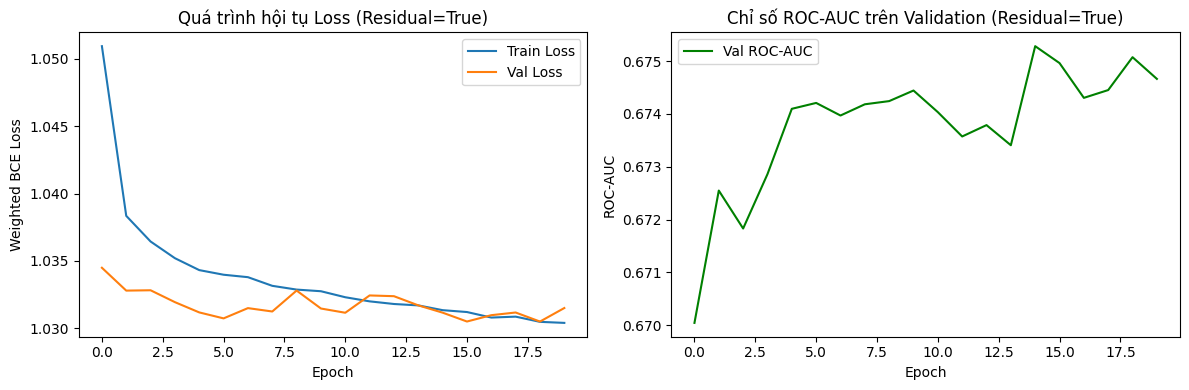


[Training] Thiết bị tính toán: cpu | Residual Enabled: False

--- [SANITY CHECK] Kiểm tra luồng gradient trên 5 mẫu dữ liệu đầu tiên ---
-> Sanity Check Loss sau 50 steps: 0.000036 (Đạt yêu cầu: tiến sát 0.0)
-> Trọng số hàm Loss tự tính (pos_weight): 4.01

--- BẮT ĐẦU VÒNG LẶP HUẤN LUYỆN ---
Epoch [01/25] | Train Loss: 1.0509 | Val Loss: 1.0367 | Val ROC-AUC: 0.6696
Epoch [02/25] | Train Loss: 1.0397 | Val Loss: 1.0333 | Val ROC-AUC: 0.6719
Epoch [03/25] | Train Loss: 1.0376 | Val Loss: 1.0350 | Val ROC-AUC: 0.6733
Epoch [04/25] | Train Loss: 1.0363 | Val Loss: 1.0327 | Val ROC-AUC: 0.6734
Epoch [05/25] | Train Loss: 1.0357 | Val Loss: 1.0314 | Val ROC-AUC: 0.6734
Epoch [06/25] | Train Loss: 1.0348 | Val Loss: 1.0304 | Val ROC-AUC: 0.6743
Epoch [07/25] | Train Loss: 1.0345 | Val Loss: 1.0319 | Val ROC-AUC: 0.6738
Epoch [08/25] | Train Loss: 1.0344 | Val Loss: 1.0310 | Val ROC-AUC: 0.6742
Epoch [09/25] | Train Loss: 1.0339 | Val Loss: 1.0339 | Val ROC-AUC: 0.6735
Epoch [10/25] | Train

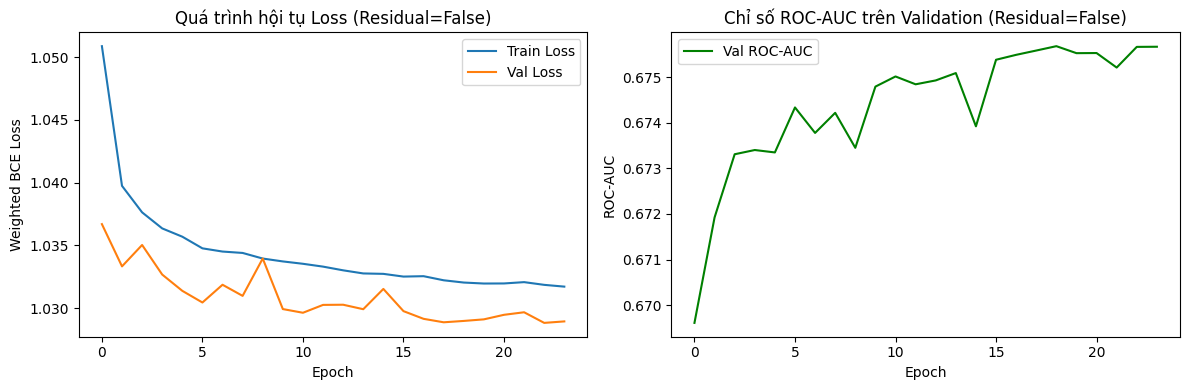

In [53]:
# Cấu hình bộ siêu tham số (Hyperparameters)
config = {
    'batch_size': 256,
    'hidden_dim': 128,
    'num_blocks': 2,
    'dropout_rate': 0.3,
    'learning_rate': 1e-3,
    'weight_decay': 1e-4,
    'min_lr': 1e-5,
    'epochs': 25,
    'patience': 5,
    'max_grad_norm': 1.0
}

# 1. Huấn luyện mô hình Residual MLP đầy đủ (Phục vụ RQ1)
model_residual, history_residual = train_deep_learning_model(
    X_train_final, y_train, X_val_final, y_val, config, use_residual=True
)

# 2. Huấn luyện biến thể Ablation Study - Bỏ Skip Connection (Phục vụ RQ3)
model_ablation, history_ablation = train_deep_learning_model(
    X_train_final, y_train, X_val_final, y_val, config, use_residual=False
)